# Lab 4: สร้างภาพเองด้วย VAE — และเทียบกับ Autoencoder ธรรมดา
**Generative AI · ช่วงบ่าย · Notebook 2**

ช่วงเช้า: **Autoencoder** บีบภาพเป็น "จุด" ใน latent space ส่วน **VAE** บีบเป็น "ช่วง" (distribution) จึงสุ่มสร้างภาพใหม่ได้
แล็บนี้เทรน **ทั้งสองแบบด้วยโค้ดชุดเดียวกัน** ต่างกันแค่เทอมเดียวใน loss แล้ววางผลเทียบกันทีละภาพ

```
ภาพ 28×28 ──Encoder──▶ (μ, log σ²) ──สุ่ม z──▶ Decoder ──▶ ภาพ 28×28
                          latent 2 มิติ
Loss = Reconstruction  +  kl_weight × KL
        VAE: kl_weight = 1        Autoencoder: kl_weight = 0
```
> ⚙️ แนะนำ **Runtime → Change runtime type → T4 GPU** (เทรน 2 โมเดลรวม ~2–3 นาที · CPU ~10 นาที)

In [10]:
import numpy as np, tensorflow as tf, keras
from keras import layers, ops
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110})

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
EPOCHS = 15 if gpus else 4
print("✅ GPU" if gpus else "⚠️ CPU", "→ EPOCHS =", EPOCHS)

TensorFlow: 2.20.0 | Keras: 3.10.0
⚠️ CPU → EPOCHS = 4


## 4.1 ข้อมูล MNIST
ตัวเลขลายมือ 0–9 ขนาด 28×28 (ชุดเดียวกับสัปดาห์ก่อน)
VAE เป็น **unsupervised**: เทรนด้วยภาพอย่างเดียว label ใช้แค่ระบายสีตอนวาดกราฟ
- `[..., None]` เพิ่มมิติ channel → (N, 28, 28, 1) ให้ Conv2D ใช้ได้
- หาร 255 ให้ค่า 0–1 เพราะ decoder ใช้ `sigmoid` และ loss เป็น binary cross-entropy

train: (60000, 28, 28, 1) | test: (10000, 28, 28, 1)


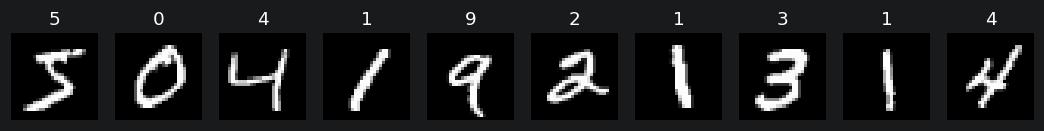

In [11]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32")[..., None] / 255.0
x_test  = x_test.astype("float32")[..., None] / 255.0
print("train:", x_train.shape, "| test:", x_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(12, 1.5))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i, :, :, 0], cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.show()

## 4.2 ส่วนประกอบ
### Sampling layer — reparameterization trick
Encoder ให้ **μ (`z_mean`)** และ **log σ² (`z_log_var`)** แล้วสุ่ม $z = \mu + \sigma \cdot \varepsilon$ โดย $\varepsilon \sim \mathcal{N}(0,1)$ และ $\sigma = e^{0.5 \log\sigma^2}$
- เก็บเป็น log σ² เพราะ σ ต้องเป็นบวกเสมอ แต่ log σ² เป็นค่าใดก็ได้ ให้ Dense ทำนายได้สะดวก
- ความสุ่มถูกแยกไปอยู่ที่ ε ซึ่งไม่ต้องหา gradient ส่วน μ และ σ อยู่ในสูตรธรรมดา → backpropagation ผ่านได้ จึงเทรน encoder ได้

In [12]:
class Sampling(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(1337)
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(shape=ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * eps

### Encoder และ Decoder
ใช้ Conv2D / Conv2DTranspose แบบที่เรียนสัปดาห์ก่อน · `latent_dim = 2` เพื่อวาด latent space บนกราฟ 2 มิติได้

| Encoder | รูปร่าง | Decoder | รูปร่าง |
|---|---|---|---|
| Input | 28×28×1 | Input z | 2 |
| Conv2D 32, stride 2 | 14×14×32 | Dense 7·7·64 → Reshape | 7×7×64 |
| Conv2D 64, stride 2 | 7×7×64 | Conv2DTranspose 64, stride 2 | 14×14×64 |
| Flatten → Dense 16 | 16 | Conv2DTranspose 32, stride 2 | 28×28×32 |
| Dense → μ, Dense → log σ² | 2, 2 | Conv2DTranspose 1, sigmoid | 28×28×1 |

ฟังก์ชัน `build_encoder_decoder()` สร้างชุดใหม่ทุกครั้งที่เรียก → VAE และ Autoencoder ได้ weight แยกกัน

In [13]:
latent_dim = 2

def build_encoder_decoder():
    enc_in = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Dense(16, activation="relu")(layers.Flatten()(x))
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    encoder = keras.Model(enc_in, [z_mean, z_log_var, Sampling()([z_mean, z_log_var])], name="encoder")

    dec_in = keras.Input(shape=(latent_dim,))
    x = layers.Reshape((7, 7, 64))(layers.Dense(7 * 7 * 64, activation="relu")(dec_in))
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
    dec_out = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(x)
    decoder = keras.Model(dec_in, dec_out, name="decoder")
    return encoder, decoder

def run(model, x):
    # เรียกโมเดลตรงๆ: เร็วกว่า .predict กับข้อมูลชุดเล็ก และไม่มีคำเตือน retracing
    out = model(np.asarray(x, dtype="float32"), training=False)
    return [o.numpy() for o in out] if isinstance(out, (list, tuple)) else out.numpy()

e, d = build_encoder_decoder()
e.summary(); d.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 14, 14,    │        320 │ input_layer_6[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 3136)      │          0 │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 16)        │     50,192 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         34 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         34 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_3          │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 69,076 (269.83 KB)

 Trainable params: 69,076 (269.83 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)

### โมเดลและ loss
เขียน `train_step` เอง เพราะ loss ต้องใช้ z_mean และ z_log_var ที่อยู่ข้างในโมเดล

| เทอม | ความหมาย |
|---|---|
| **Reconstruction** | ภาพที่สร้างกลับเหมือนภาพจริงแค่ไหน — binary cross-entropy ทีละพิกเซล รวมทั้งภาพ แล้วเฉลี่ยทั้ง batch |
| **KL divergence** | ระยะห่างระหว่าง N(μ, σ²) กับ N(0, 1): $-\tfrac12\sum(1+\log\sigma^2-\mu^2-\sigma^2)$ → ดึงทุกภาพให้อยู่รอบจุดศูนย์กลาง และไม่ให้ σ หดเป็นศูนย์ |

`kl_weight` คือสวิตช์: **1 = VAE** · **0 = Autoencoder ธรรมดา** (ไม่มีอะไรบังคับรูปร่างของ latent)
- `tf.GradientTape()` บันทึกการคำนวณไว้หา gradient → `apply_gradients` ให้ Adam ปรับ weight (backpropagation แบบสัปดาห์ก่อน)

In [14]:
class LatentModel(keras.Model):
    def __init__(self, encoder, decoder, kl_weight, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.kl_weight = encoder, decoder, kl_weight
        self.trackers = {k: keras.metrics.Mean(name=k) for k in ["loss", "reconstruction", "kl"]}

    @property
    def metrics(self):
        return list(self.trackers.values())

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            recon = self.decoder(z)
            recon_loss = ops.mean(ops.sum(keras.losses.binary_crossentropy(data, recon), axis=(1, 2)))
            kl = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
            kl_loss = ops.mean(ops.sum(kl, axis=1))
            loss = recon_loss + self.kl_weight * kl_loss
        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        for k, v in zip(["loss", "reconstruction", "kl"], [loss, recon_loss, kl_loss]):
            self.trackers[k].update_state(v)
        return {k: t.result() for k, t in self.trackers.items()}

def train(kl_weight, name):
    enc, dec = build_encoder_decoder()
    model = LatentModel(enc, dec, kl_weight)
    model.compile(optimizer=keras.optimizers.Adam(1e-3))
    print(f"\n=== เทรน {name} (kl_weight={kl_weight}) ===")
    hist = model.fit(x_train, epochs=EPOCHS, batch_size=128, verbose=2)
    return model, hist

## 4.3 เทรนทั้งสองแบบ


=== เทรน VAE (kl_weight=1.0) ===
Epoch 1/4
469/469 - 7s - 16ms/step - kl: 2.8919 - loss: 213.9113 - reconstruction: 211.0194
Epoch 2/4
469/469 - 7s - 15ms/step - kl: 3.2158 - loss: 189.3439 - reconstruction: 186.1282
Epoch 3/4
469/469 - 7s - 15ms/step - kl: 3.6249 - loss: 183.5886 - reconstruction: 179.9637
Epoch 4/4
469/469 - 7s - 15ms/step - kl: 5.7524 - loss: 168.4820 - reconstruction: 162.7295

=== เทรน Autoencoder (kl_weight=0.0) ===
Epoch 1/4
469/469 - 8s - 16ms/step - kl: 72.8751 - loss: 209.4414 - reconstruction: 209.4414
Epoch 2/4
469/469 - 7s - 15ms/step - kl: 194.9820 - loss: 169.0784 - reconstruction: 169.0784
Epoch 3/4
469/469 - 7s - 15ms/step - kl: 189.5048 - loss: 161.4450 - reconstruction: 161.4450
Epoch 4/4
469/469 - 7s - 15ms/step - kl: 172.9161 - loss: 156.8892 - reconstruction: 156.8892


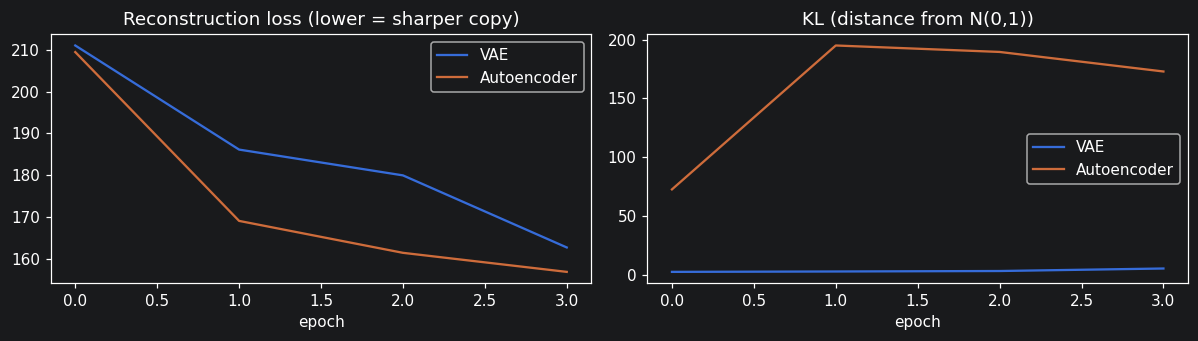

In [15]:
vae, hist_vae = train(1.0, "VAE")
ae,  hist_ae  = train(0.0, "Autoencoder")
MODELS = {"VAE": vae, "Autoencoder": ae}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, h in [("VAE", hist_vae), ("Autoencoder", hist_ae)]:
    axes[0].plot(h.history["reconstruction"], label=name)
    axes[1].plot(h.history["kl"], label=name)
axes[0].set_title("Reconstruction loss (lower = sharper copy)"); axes[1].set_title("KL (distance from N(0,1))")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- **Reconstruction:** Autoencoder มักต่ำกว่า (ลอกภาพเดิมได้ดีกว่า) เพราะไม่ต้องแบ่ง "ความจุ" ไปจัดระเบียบ latent
- **KL:** ของ Autoencoder สูงมาก/เพิ่มขึ้น เพราะไม่มีอะไรดึง latent ให้อยู่ใกล้ N(0,1) · ของ VAE ถูกคุมให้ต่ำ
- คำถามสำคัญคือ **ข้อแลกเปลี่ยนนี้ได้อะไร** → ดูภาพถัดไป

## 4.4 เปรียบเทียบ ① การสร้างภาพเดิมกลับ (reconstruction)
ใช้ μ (`z_mean`) ของภาพทดสอบ แล้วให้ decoder วาดกลับ

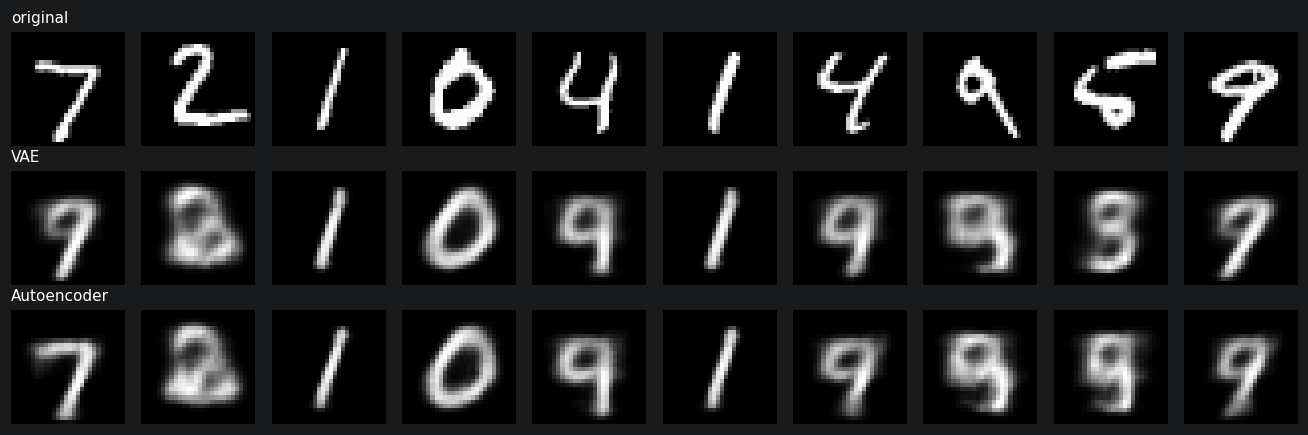

In [7]:
n = 10
fig, axes = plt.subplots(3, n, figsize=(12, 4))
for i in range(n):
    axes[0, i].imshow(x_test[i, :, :, 0], cmap="gray")
for r, (name, m) in enumerate(MODELS.items(), start=1):
    z, _, _ = run(m.encoder, x_test[:n])
    rec = run(m.decoder, z)
    for i in range(n):
        axes[r, i].imshow(rec[i, :, :, 0], cmap="gray")
for ax in axes.flat: ax.axis("off")
for r, t in enumerate(["original", "VAE", "Autoencoder"]):
    axes[r, 0].set_title(t, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร:** ทั้งสองแบบวาดภาพเดิมกลับได้ใกล้เคียงกัน (เบลอเพราะบีบ 784 พิกเซลเหลือ 2 ตัวเลข) — **ถ้าดูแค่ข้อนี้ จะไม่เห็นความต่าง** ความต่างอยู่ที่ "การสร้างของใหม่"

## 4.5 เปรียบเทียบ ② Latent space
นำภาพทดสอบทั้งหมดผ่าน encoder แล้วพล็อต μ ของแต่ละภาพ ระบายสีตามตัวเลขจริง · วงประคือบริเวณที่ N(0,1) สุ่มตกบ่อย (รัศมี 2)

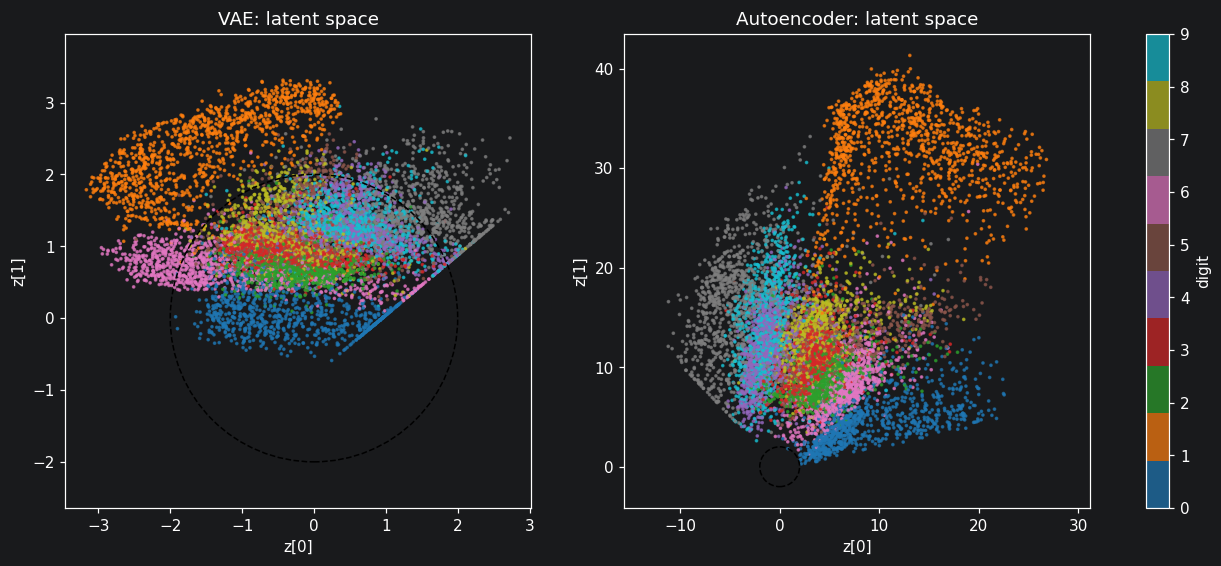

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, (name, m) in zip(axes, MODELS.items()):
    z, _, _ = run(m.encoder, x_test)
    sc = ax.scatter(z[:, 0], z[:, 1], c=y_test, cmap="tab10", s=2, alpha=0.7)
    ax.add_patch(plt.Circle((0, 0), 2, fill=False, ls="--", color="k"))
    ax.set_title(f"{name}: latent space"); ax.set_xlabel("z[0]"); ax.set_ylabel("z[1]"); ax.set_aspect("equal", "datalim")
plt.colorbar(sc, ax=axes, ticks=range(10), label="digit", fraction=0.025)
plt.show()

**อ่านผลอย่างไร**
- ทั้งคู่ **จัดกลุ่มตัวเลขได้เองโดยไม่เคยเห็น label** (สีเดียวกันอยู่ด้วยกัน)
- **VAE:** จุดทั้งหมดอัดแน่นอยู่ในวงประ รอบ (0,0) ต่อเนื่อง ไม่มีช่องว่าง — ผลของ KL
- **Autoencoder:** จุดกระจายกว้าง สเกลต่างออกไปมาก มีช่องว่างระหว่างกลุ่ม และส่วนใหญ่อยู่นอกวงประ

## 4.6 เปรียบเทียบ ③ "แผนที่ตัวเลข": ให้ decoder วาดทุกจุดบนตาราง [-2, 2]

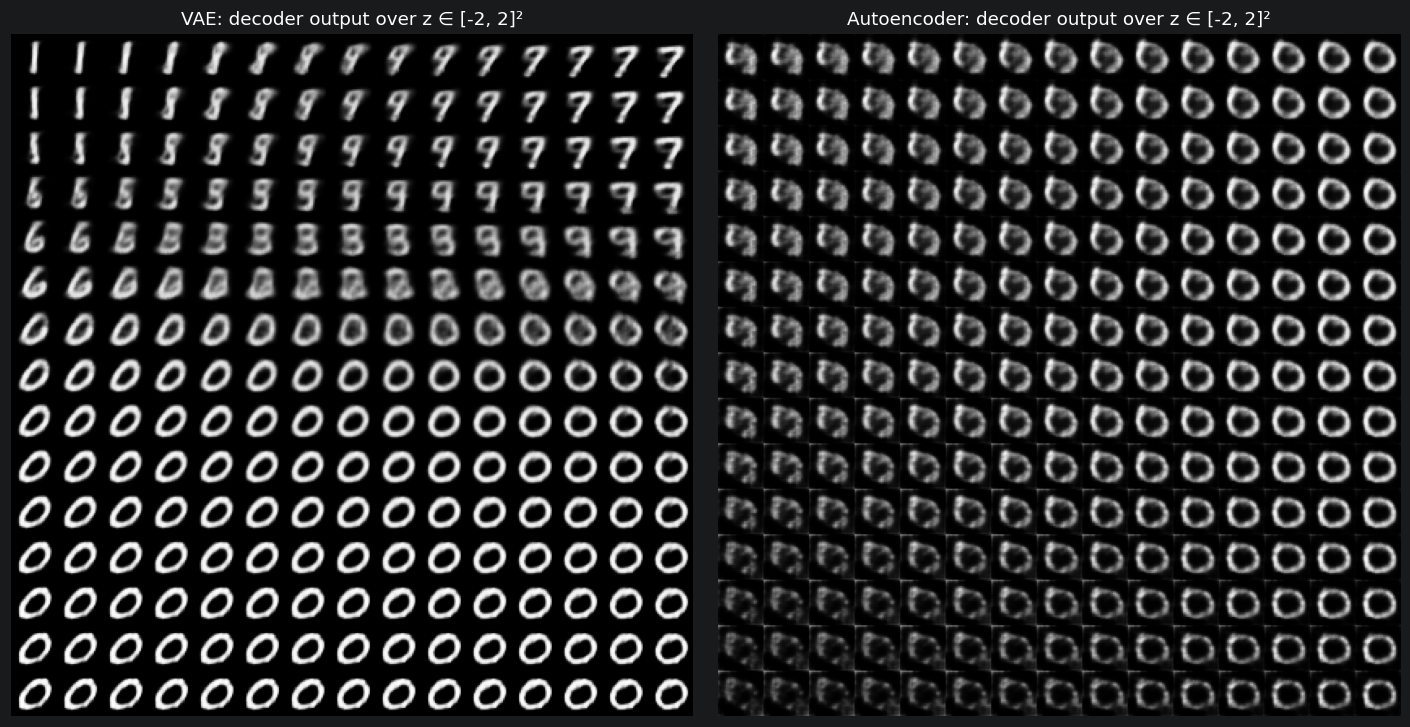

In [17]:
def latent_grid(decoder, n=15, scale=2.0):
    grid = np.linspace(-scale, scale, n)
    zs = np.array([[x, y] for y in grid[::-1] for x in grid])
    imgs = run(decoder, zs)[:, :, :, 0]
    return imgs.reshape(n, n, 28, 28).transpose(0, 2, 1, 3).reshape(n * 28, n * 28)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (name, m) in zip(axes, MODELS.items()):
    ax.imshow(latent_grid(m.decoder), cmap="Greys_r"); ax.axis("off")
    ax.set_title(f"{name}: decoder output over z ∈ [-2, 2]²")
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร**
- **VAE:** ทุกจุดบนตารางเป็นตัวเลขที่อ่านได้ และค่อยๆ เปลี่ยนรูปเมื่อเลื่อน (เช่น 0 → 6 → 5) — latent space "เรียบ" เหมือนแผนที่ในสไลด์ตอนเช้า
- **Autoencoder:** บริเวณนี้อาจเป็นเพียงมุมเล็กๆ ของ latent หรือเป็นช่องว่างที่ไม่มีข้อมูลจริง ภาพจึงซ้ำ แปลก หรือเละ

## 4.7 เปรียบเทียบ ④ สร้างตัวเลขใหม่: สุ่ม z ~ N(0, 1)
นี่คือ "การสร้าง" จริงของ generative model: สุ่มจุดใหม่แล้วถอดรหัส โดยไม่ต้องมีภาพต้นฉบับ

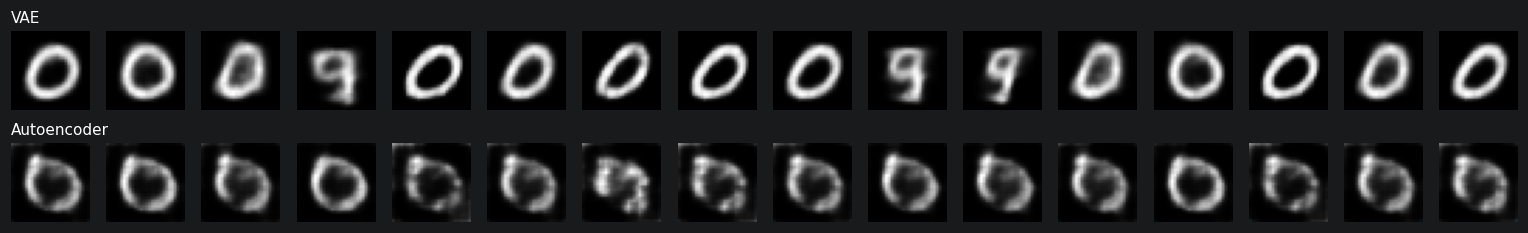

In [18]:
rng = np.random.default_rng(0)
z_random = rng.normal(size=(16, latent_dim))
fig, axes = plt.subplots(2, 16, figsize=(14, 2.3))
for r, (name, m) in enumerate(MODELS.items()):
    imgs = run(m.decoder, z_random)
    for i in range(16):
        axes[r, i].imshow(imgs[i, :, :, 0], cmap="gray"); axes[r, i].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร:** จุดสุ่มชุดเดียวกัน (`z_random`) ป้อนให้ทั้งสอง decoder
- **VAE** ได้ตัวเลขที่ดูสมเหตุสมผลเกือบทุกภาพ เพราะถูกเทรนให้บริเวณ N(0,1) เต็มไปด้วยข้อมูล
- **Autoencoder** ได้ภาพที่ซ้ำหรือไม่เป็นตัวเลขบ่อยกว่า เพราะจุดสุ่มมักตกในบริเวณที่ encoder ไม่เคยใช้

## 4.8 เปรียบเทียบ ⑤ Interpolation: เดินเป็นเส้นตรงจากเลข 1 ไปเลข 7

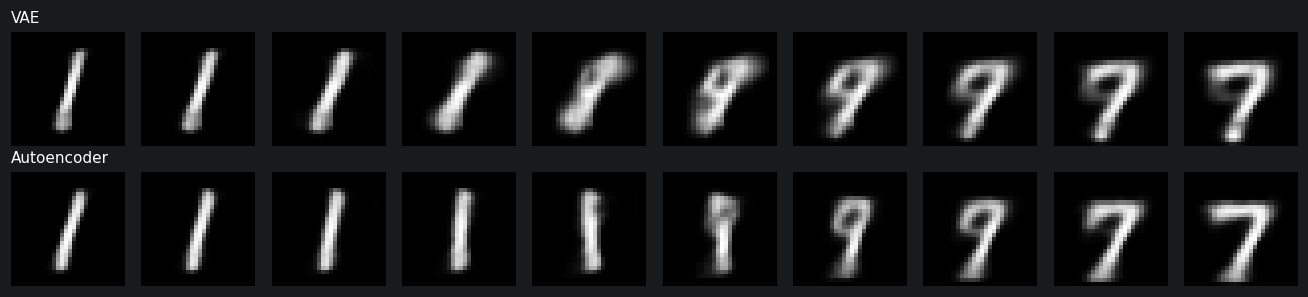

In [19]:
a = int(np.where(y_test == 1)[0][0]); b = int(np.where(y_test == 7)[0][0])
steps = 10
fig, axes = plt.subplots(2, steps, figsize=(12, 2.8))
for r, (name, m) in enumerate(MODELS.items()):
    za = run(m.encoder, x_test[a:a+1])[0][0]
    zb = run(m.encoder, x_test[b:b+1])[0][0]
    zs = np.array([(1 - t) * za + t * zb for t in np.linspace(0, 1, steps)])
    imgs = run(m.decoder, zs)
    for i in range(steps):
        axes[r, i].imshow(imgs[i, :, :, 0], cmap="gray"); axes[r, i].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**อ่านผลอย่างไร:** VAE มักแปลงร่าง 1 → 7 อย่างค่อยเป็นค่อยไป เพราะเส้นทางระหว่างสองจุดผ่านบริเวณที่มีความหมาย ส่วน Autoencoder อาจผ่าน "ช่องว่าง" ทำให้ภาพกลางทางแปลก

---
## ✅ สรุป Notebook 2
| | Autoencoder | VAE |
|---|---|---|
| Latent | จุดเดียวต่อภาพ กระจาย มีช่องว่าง | distribution ต่อภาพ อัดแน่นรอบ N(0,1) |
| Loss | reconstruction อย่างเดียว | reconstruction + KL |
| ลอกภาพเดิม | ดี | ดี (เบลอกว่าเล็กน้อย) |
| **สุ่มสร้างภาพใหม่** | ❌ ไม่น่าเชื่อถือ | ✅ ได้ |

- ความต่างทั้งหมดมาจาก **เทอม KL เทอมเดียว** — นี่คือเหตุผลที่ VAE เป็น *generative* model
- ภาพเบลอคือข้อจำกัดของ VAE ที่ GAN และ Diffusion แก้ได้ดีกว่า
- Stable Diffusion ทำ diffusion **ใน latent space ของ autoencoder** แทนการทำบนพิกเซลโดยตรง หลักการ "ถอดรหัสจาก latent" ในแล็บนี้จึงเป็นส่วนหนึ่งของโมเดลสร้างภาพสมัยใหม่

📚 **การบ้าน:** Notebook 3 (`Lab5_Homework.ipynb`)